# EDA – Explorative Datenanalyse

*(Deutsche Version des Start-Notebooks `04_eda.ipynb`. Der Code ist unverändert, es wurden nur deutsche Kommentare ergänzt.)*

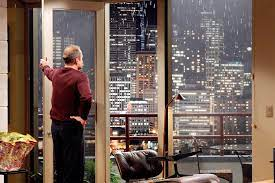

In [1]:
# Pakete laden
import warnings

import matplotlib.pyplot as plt  # für Diagramme
import pandas as pd  # für Tabellen (DataFrames)

# Warnmeldungen ausblenden, damit das Notebook übersichtlich bleibt
warnings.filterwarnings("ignore")

# Standard-Aussehen für alle Diagramme: Größe 8 x 5, weißer Hintergrund, schwarzer Rahmen
plt.rcParams.update(
    {"figure.figsize": (8, 5), "axes.facecolor": "white", "axes.edgecolor": "black"}
)
plt.rcParams["figure.facecolor"] = "w"
pd.plotting.register_matplotlib_converters()

# Kommazahlen in Tabellen immer mit 3 Nachkommastellen anzeigen
pd.set_option("display.float_format", lambda x: "%.3f" % x)

## Checkliste – Nicole Johnson

**Kunde:** Frau Nicole Johnson (Käuferin)
**Wünsche:** zentrale Gegend, lebendig, mittlere Preisklasse, Kauf innerh. 1 Jahr

### Meine Annahmen
- [ ] „Zentral“ = nah am Stadtzentrum von Seattle (Downtown)
- [ ] „Mittlere Preisklasse“ = die mittleren 50 % aller Preise
- [ ] „Lebendig“ = Gegend (Postleitzahl) mit vielen Hausverkäufen
- [ ] „Richtiger Zeitpunkt“ = der günstigste Monat im Jahr

### Meine 3 Hypothesen
- [ ] H1: Je näher ein Haus am Stadtzentrum liegt, desto teurer ist dieser.
- [ ] H2: Im Winter sind die Häuser günstiger als im Sommer.
- [ ] H3: Es gibt Häuser in zentralen Gegenden, die dennoch in der mittleren Preisklasse liegen können.

### Ablauf
- [ ] 1. Laden: die Datei eda.csv einlesen
- [ ] 2. Anschauen: Wie viele Zeilen und Spalten? Welche Spalten gibt es? Fehlen Werte?
- [ ] 3. Bereinigen: Datum umwandeln, fehlende Werte und Doppelte prüfen, seltsame Werte finden
- [ ] 4. Fragen stellen: Annahmen und Hypothesen festlegen (siehe oben)
- [ ] 5. Beantworten: für jede Hypothese Zahlen berechnen
- [ ] 6. Zeigen: für jede Hypothese ein Diagramm
- [ ] 7. Erklären: zu jedem Diagramm ein Satz, dazu 3 Erkenntnisse (eine davon geografisch) und 3 Empfehlungen für Nicole

### Abgabe
- [ ] Notebook mit Kommentaren auf GitHub
- [ ] README.md aktualisieren
- [ ] Präsentation (10 Minuten) als PDF auf GitHub

## Pseudocode

**1. Laden**
- STORE Datei data/eda.csv in df

**2. Anschauen**
- OUTPUT die ersten 5 Zeilen
- OUTPUT Anzahl Zeilen und Spalten
- OUTPUT Spaltentypen und fehlende Werte
- OUTPUT Statistik aller Spalten

**3. Bereinigen**
- STORE Spalte date als echtes Datum
- STORE neue Spalte monat aus date
- OUTPUT Anzahl fehlender Werte pro Spalte
- OUTPUT Anzahl doppelter Zeilen
- IF es gibt unmögliche Werte (z. B. sehr viele Schlafzimmer) THEN entfernen

**4. Fragen stellen**
- STORE Mittelpunkt von Seattle (Breitengrad, Längengrad)
- STORE neue Spalte entfernung = Abstand jedes Hauses zum Zentrum
- STORE untere Grenze = 25 % aller Preise
- STORE obere Grenze = 75 % aller Preise

**5. Beantworten**
- H1: OUTPUT Zusammenhang zwischen entfernung und price
- H2: FOR jeden Monat: OUTPUT Median-Preis
- H3: STORE zentrale Häuser (entfernung klein), davon nur Häuser zwischen unterer und oberer Grenze, OUTPUT Anzahl und Postleitzahlen

**6. Zeigen**
- H1: Streudiagramm entfernung gegen price
- H2: Balkendiagramm Median-Preis pro Monat
- H3: Streudiagramm (Längengrad, Breitengrad) der passenden Häuser

**7. Erklären**
- Zu jedem Diagramm einen Satz schreiben
- H1, H2, H3 jeweils mit wahr / falsch beantworten
- 3 Erkenntnisse und 3 Empfehlungen für Nicole formulieren

In [2]:
# SKELETT: alle Funktionen, noch ohne Inhalt

# 1. Laden
def daten_laden():
    pass

# 2. Anschauen
def daten_anschauen(df):
    pass

# 3. Bereinigen
def daten_bereinigen(df):
    pass

# 4. Fragen aufstellen: neue Spalten und Grenzen
def entfernung_berechnen(df):
    pass

def preisgrenzen_berechnen(df):
    pass

# 5. Beantworten
def hypothese_1_pruefen(df):
    pass

def hypothese_2_pruefen(df):
    pass

def hypothese_3_pruefen(df, untere_grenze, obere_grenze):
    pass

# 6. Zeigen
def diagramm_h1(df):
    pass

def diagramm_h2(df):
    pass

def diagramm_h3(df, untere_grenze, obere_grenze):
    pass

In [3]:
# 1. Laden
def daten_laden():
    # CSV-Datei aus dem Ordner data einlesen
    df = pd.read_csv("data/eda.csv")
    # Die Tabelle zurückgeben
    return df


# Funktion benutzen
df = daten_laden()

# Die ersten 5 Zeilen anzeigen
df.head()

,date,price,id,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,'2014-10-13',221900.000,7129300520,3.000,1.000,1180.000,5650.000,1.000,NaN,0.000,...,7,1180.000,0.000,1955,0.000,98178,47.511,-122.257,1340.000,5650.000
1,'2014-12-09',538000.000,6414100192,3.000,2.250,2570.000,7242.000,2.000,0.000,0.000,...,7,2170.000,400.000,1951,19910.000,98125,47.721,-122.319,1690.000,7639.000
2,'2015-02-25',180000.000,5631500400,2.000,1.000,770.000,10000.000,1.000,0.000,0.000,...,6,770.000,0.000,1933,NaN,98028,47.738,-122.233,2720.000,8062.000
3,'2014-12-09',604000.000,2487200875,4.000,3.000,1960.000,5000.000,1.000,0.000,0.000,...,7,1050.000,910.000,1965,0.000,98136,47.521,-122.393,1360.000,5000.000
4,'2015-02-18',510000.000,1954400510,3.000,2.000,1680.000,8080.000,1.000,0.000,0.000,...,8,1680.000,0.000,1987,0.000,98074,47.617,-122.045,1800.000,7503.000


In [4]:
# 2. Anschauen
def daten_anschauen(df):
    # Wie viele Zeilen und Spalten?
    print("Zeilen und Spalten:", df.shape)

    # Welche Spalten und Datentypen gibt es?
    df.info()

    # Wie viele Werte fehlen pro Spalte?
    print(df.isna().sum())


daten_anschauen(df)

Zeilen und Spalten: (21597, 21)
<class 'pandas.DataFrame'>
RangeIndex: 21597 entries, 0 to 21596
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   date           21597 non-null  str    
 1   price          21597 non-null  float64
 2   id             21597 non-null  int64  
 3   bedrooms       21597 non-null  float64
 4   bathrooms      21597 non-null  float64
 5   sqft_living    21597 non-null  float64
 6   sqft_lot       21597 non-null  float64
 7   floors         21597 non-null  float64
 8   waterfront     19206 non-null  float64
 9   view           21534 non-null  float64
 10  condition      21597 non-null  int64  
 11  grade          21597 non-null  int64  
 12  sqft_above     21597 non-null  float64
 13  sqft_basement  21145 non-null  float64
 14  yr_built       21597 non-null  int64  
 15  yr_renovated   17749 non-null  float64
 16  zipcode        21597 non-null  int64  
 17  lat            21597 non-null

In [5]:
# Statistik der Zahlen-Spalten # ein Bedroom mit 33 Zimmer ist unwahrscheinlich --> Fehler
df.describe()

,price,id,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
count,21597.000,21597.000,21597.000,21597.000,21597.000,21597.000,21597.000,19206.000,21534.000,21597.000,21597.000,21597.000,21145.000,21597.000,17749.000,21597.000,21597.000,21597.000,21597.000,21597.000
mean,540296.574,4580474287.771,3.373,2.116,2080.322,15099.409,1.494,0.008,0.234,3.410,7.658,1788.597,291.857,1971.000,836.651,98077.952,47.560,-122.214,1986.620,12758.284
std,367368.140,2876735715.748,0.926,0.769,918.106,41412.637,0.540,0.087,0.766,0.651,1.173,827.760,442.491,29.375,4000.111,53.513,0.139,0.141,685.230,27274.442
min,78000.000,1000102.000,1.000,0.500,370.000,520.000,1.000,0.000,0.000,1.000,3.000,370.000,0.000,1900.000,0.000,98001.000,47.156,-122.519,399.000,651.000
25%,322000.000,2123049175.000,3.000,1.750,1430.000,5040.000,1.000,0.000,0.000,3.000,7.000,1190.000,0.000,1951.000,0.000,98033.000,47.471,-122.328,1490.000,5100.000
50%,450000.000,3904930410.000,3.000,2.250,1910.000,7618.000,1.500,0.000,0.000,3.000,7.000,1560.000,0.000,1975.000,0.000,98065.000,47.572,-122.231,1840.000,7620.000
75%,645000.000,7308900490.000,4.000,2.500,2550.000,10685.000,2.000,0.000,0.000,4.000,8.000,2210.000,560.000,1997.000,0.000,98118.000,47.678,-122.125,2360.000,10083.000
max,7700000.000,9900000190.000,33.000,8.000,13540.000,1651359.000,3.500,1.000,4.000,5.000,13.000,9410.000,4820.000,2015.000,20150.000,98199.000,47.778,-121.315,6210.000,871200.000


In [6]:
# 3. Bereinigen
def daten_bereinigen(df):  # Kap. 13 eigene Notizen
    # Hochkommas aus dem Datum entfernen
    df["date"] = df["date"].str.replace("'", "")  # Kap. 17 (.str)

    # Text in ein echtes Datum umwandeln
    df["date"] = pd.to_datetime(df["date"])  # Kap. 19

    # Neue Spalte: Verkaufsmonat (1 = Januar, 12 = Dezember)
    df["monat"] = df["date"].dt.month  # Kap. 19 (.dt)

    # Doppelte Zeilen zählen
    print("Doppelte Zeilen:", df.duplicated().sum())  # Kap. 17

    # Größte Anzahl Schlafzimmer anzeigen
    print("Meiste Schlafzimmer:", df["bedrooms"].max())  # Kap. 15

    # Unrealistische Häuser entfernen (30 oder mehr Schlafzimmer)
    df = df[df["bedrooms"] < 30]  # Kap. 16 (Filtern)

    return df  # Kap. 13 (return)


df = daten_bereinigen(df)
df.head()  # Kap. 15

Doppelte Zeilen: 0
Meiste Schlafzimmer: 33.0


,date,price,id,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15,monat
0,2014-10-13,221900.000,7129300520,3.000,1.000,1180.000,5650.000,1.000,NaN,0.000,...,1180.000,0.000,1955,0.000,98178,47.511,-122.257,1340.000,5650.000,10
1,2014-12-09,538000.000,6414100192,3.000,2.250,2570.000,7242.000,2.000,0.000,0.000,...,2170.000,400.000,1951,19910.000,98125,47.721,-122.319,1690.000,7639.000,12
2,2015-02-25,180000.000,5631500400,2.000,1.000,770.000,10000.000,1.000,0.000,0.000,...,770.000,0.000,1933,NaN,98028,47.738,-122.233,2720.000,8062.000,2
3,2014-12-09,604000.000,2487200875,4.000,3.000,1960.000,5000.000,1.000,0.000,0.000,...,1050.000,910.000,1965,0.000,98136,47.521,-122.393,1360.000,5000.000,12
4,2015-02-18,510000.000,1954400510,3.000,2.000,1680.000,8080.000,1.000,0.000,0.000,...,1680.000,0.000,1987,0.000,98074,47.617,-122.045,1800.000,7503.000,2


In [7]:
# 4.0 Fragen aufstellen: Entfernung zum Zentrum ?
def entfernung_berechnen(df):  # Kap. 13
    # Koordinaten von Downtown Seattle 
    zentrum_lat = 47.6062  # Kap. 4 (Variablen)
    zentrum_long = -122.3321  # Kap. 4

    # Abstand nach Norden/Süden in km (1 Grad = ca. 111 km)
    abstand_nord_sued = (df["lat"] - zentrum_lat) * 111  # Kap. 4, 17

    # Abstand nach Osten/Westen in km (hier 1 Grad = ca. 75 km)
    abstand_ost_west = (df["long"] - zentrum_long) * 75  # Kap. 4, 17

    # Satz des Pythagoras: Luftlinie in km
    df["entfernung_km"] = (
        abstand_nord_sued ** 2 + abstand_ost_west ** 2
    ) ** 0.5  # Kap. 4 (Rechnen), Kap. 17 (neue Spalte)

    return df  # Kap. 13


df = entfernung_berechnen(df)

# Kontrolle: kleinste, mittlere und größte Entfernung
print("Kleinste Entfernung:", df["entfernung_km"].min())  # Kap. 15
print("Mittlere Entfernung:", df["entfernung_km"].median())  # Kap. 15
print("Größte Entfernung:", df["entfernung_km"].max())  # Kap. 15

Kleinste Entfernung: 0.983502724957667
Mittlere Entfernung: 16.496128656748176
Größte Entfernung: 77.19816117816531


In [8]:
# 4.1 Frage: Preisgrenzen der mittleren Preisklasse ?
def preisgrenzen_berechnen(df):  # Kap. 13
    # 25 % der Häuser sind billiger als diese Grenze
    untere_grenze = df["price"].quantile(0.25)  # Kap. 15

    # 75 % der Häuser sind billiger als diese Grenze
    obere_grenze = df["price"].quantile(0.75)  # Kap. 15

    # Beide Grenzen zurückgeben
    return untere_grenze, obere_grenze  # Kap. 13, Kap. 9 (Tupel)


untere_grenze, obere_grenze = preisgrenzen_berechnen(df)  # Kap. 9

print("Untere Grenze:", untere_grenze)  # Kap. 4
print("Obere Grenze:", obere_grenze)  # Kap. 4

Untere Grenze: 322000.0
Obere Grenze: 645000.0


In [9]:
# 5. Beantworten: Hypothese 1 beantworten
def hypothese_1_pruefen(df):  # Kap. 13
    # Zusammenhang zwischen Entfernung und Preis (Korrelation)
    korrelation = df["entfernung_km"].corr(df["price"])  # Kap. 15
    print("Korrelation Entfernung und Preis:", korrelation)  # Kap. 4

    # Häuser bis 10 km vom Zentrum
    nah = df[df["entfernung_km"] <= 10]  # Kap. 16 (Filtern)

    # Häuser weiter als 10 km vom Zentrum
    weit = df[df["entfernung_km"] > 10]  # Kap. 16

    # Median-Preis für beide Gruppen
    print("Median-Preis bis 10 km:", nah["price"].median())  # Kap. 15
    print("Median-Preis über 10 km:", weit["price"].median())  # Kap. 15


hypothese_1_pruefen(df)

Korrelation Entfernung und Preis: -0.2861768390567841
Median-Preis bis 10 km: 555000.0
Median-Preis über 10 km: 416000.0


In [10]:
# 5. Beantworten: Hypothese 2 beantworten
def hypothese_2_pruefen(df):  # Kap. 13
    # Median-Preis für jeden Monat
    preis_pro_monat = df.groupby("monat")["price"].median()  # Kap. 17
    print("Median-Preis pro Monat:")  # Kap. 4
    print(preis_pro_monat)  # Kap. 4

    # Winter: Dezember, Januar, Februar
    winter = df[(df["monat"] == 12) | (df["monat"] == 1) | (df["monat"] == 2)]  # Kap. 16

    # Sommer: Juni, Juli, August
    sommer = df[(df["monat"] == 6) | (df["monat"] == 7) | (df["monat"] == 8)]  # Kap. 16

    # Median-Preis für beide Jahreszeiten
    print("Median-Preis Winter:", winter["price"].median())  # Kap. 15
    print("Median-Preis Sommer:", sommer["price"].median())  # Kap. 15


hypothese_2_pruefen(df)

Median-Preis pro Monat:
monat
1    438500.000
2    426500.000
3    450000.000
4    477000.000
5    462000.000
6    465000.000
7    465000.000
8    442200.000
9    450000.000
10   447000.000
11   435000.000
12   432500.000
Name: price, dtype: float64
Median-Preis Winter: 430000.0
Median-Preis Sommer: 455000.0


In [11]:
# 5. Beantworten: Hypothese 3 beantworten
def hypothese_3_pruefen(df, untere_grenze, obere_grenze):  # Kap. 13
    # Nur zentrale Häuser (bis 10 km)
    zentral = df[df["entfernung_km"] <= 10]  # Kap. 16

    # Davon nur Häuser, die mindestens die untere Grenze kosten
    passend = zentral[zentral["price"] >= untere_grenze]  # Kap. 16

    # Davon nur Häuser, die höchstens die obere Grenze kosten
    passend = passend[passend["price"] <= obere_grenze]  # Kap. 16

    # Anzahl ausgeben
    print("Zentrale Häuser (bis 10 km):", len(zentral))  # Kap. 13
    print("Davon in mittlerer Preisklasse:", len(passend))  # Kap. 13

    # Anteil in Prozent
    anteil = len(passend) / len(zentral) * 100  # Kap. 4
    print("Anteil in Prozent:", round(anteil, 1))  # Kap. 4

    # Postleitzahlen mit den meisten passenden Häusern
    print("Top 5 Postleitzahlen:")  # Kap. 4
    print(passend["zipcode"].value_counts().head(5))  # Kap. 15

    return passend  # Kap. 13


passende_haeuser = hypothese_3_pruefen(df, untere_grenze, obere_grenze)

Zentrale Häuser (bis 10 km): 5629
Davon in mittlerer Preisklasse: 2990
Anteil in Prozent: 53.1
Top 5 Postleitzahlen:
zipcode
98103    311
98115    274
98117    250
98118    249
98144    221
Name: count, dtype: int64


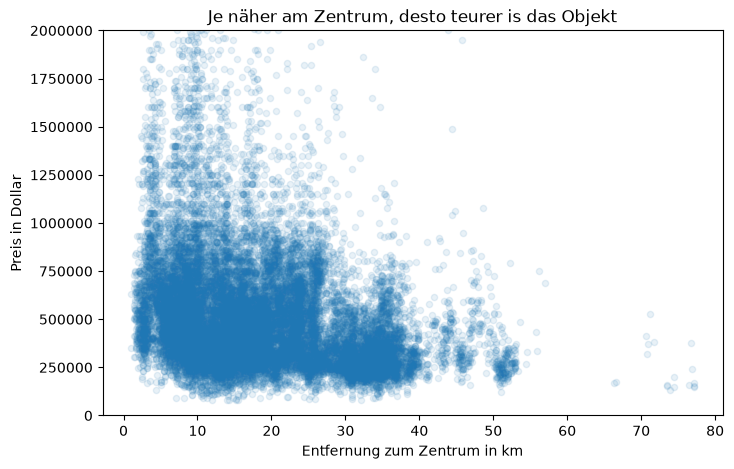

In [ ]:
# 6. Zeigen: Diagramm für Hypothese 1
def diagramm_h1(df):  # Kap. 13
    # Streudiagramm: jeder Punkt ist ein Haus
    df.plot(kind="scatter", x="entfernung_km", y="price", alpha=0.1)  # Kap. 20

    # Titel und Achsen beschriften
    plt.title("Je näher am Zentrum, desto teurer is das Objekt")  # Kap. 20
    plt.xlabel("Entfernung zum Zentrum in km")  # Kap. 20
    plt.ylabel("Preis in Dollar")  # Kap. 20

    # Nur Preise bis 2 Millionen zeigen, damit man mehr erkennen kann
    plt.ylim(0, 2000000)  # Kap. 20
    plt.ticklabel_format(axis="y", style="plain")  # Zahlen ohne 1e6 anzeigen, besser für Lesbarkeit Kap. 20

    # Diagramm anzeigen
    plt.show()  # Kap. 20


diagramm_h1(df)

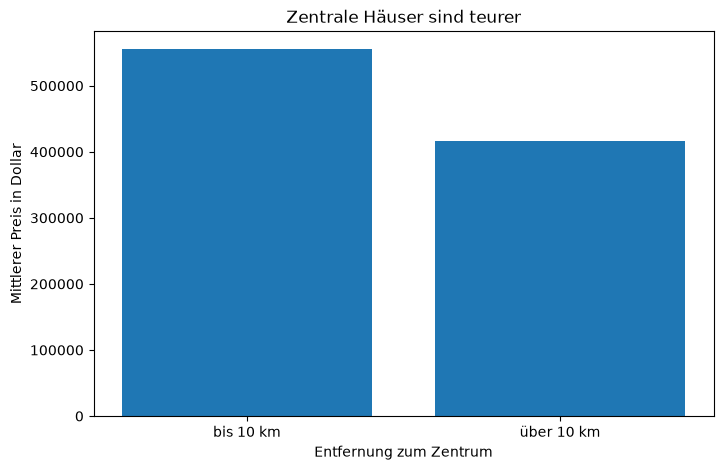

In [ ]:
# 6. Zeigen: Balkendiagramm für Hypothese 1 (leicher zum lesen)
def diagramm_h1_balken(df):  # Kap. 13
    # Häuser bis 10 km vom Zentrum
    zentral = df[df["entfernung_km"] <= 10]  # Kap. 16
    # Häuser weiter als 10 km vom Zentrum
    aussen = df[df["entfernung_km"] > 10]  # Kap. 16

    # Mittleren Preis (Median) der zentralen Häuser berechnen
    median_zentral = zentral["price"].median()  # Kap. 15
    # Mittleren Preis (Median) der äußeren Häuser berechnen
    median_aussen = aussen["price"].median()  # Kap. 15

    # Namen der beiden Balken
    gruppen = ["bis 10 km", "über 10 km"]  # Kap. 8
    # Höhe der beiden Balken
    preise = [median_zentral, median_aussen]  # Kap. 8

    # Balkendiagramm zeichnen
    plt.bar(gruppen, preise)  # Kap. 20

    # Titel und Achsen beschriften
    plt.title("Zentrale Häuser sind teurer")  # Kap. 20
    plt.xlabel("Entfernung zum Zentrum")  # Kap. 20
    plt.ylabel("Mittlerer Preis in Dollar")  # Kap. 20

    # Zahlen ohne 1e6 anzeigen
    plt.ticklabel_format(axis="y", style="plain")  # Kap. 20

    # Diagramm anzeigen
    plt.show()  # Kap. 20


diagramm_h1_balken(df)

### Ergebnis Hypothese 1: Je näher am Zentrum, desto teurer ###

**Was sieht man?**
- Ein Objekt in Zentrumnähe (bis 10 km) kostet ca. **555.000 $**.
- Ein Objekt weiter draußen kostet ca. **416.000 $**.
- Der Unterschied beträgt rund **139.000 Dollar**. Ein Objekt nah am Zentrum ist also um etwa 139K Dollar teurer.
- Die teuren Objekte stehen fast alle nah am Zentrum.
- Jedoch gibt es dennoch viele Objekte nah am Zentrum, die nicht so teuer sind.

**Was bedeutet das für Nicole?**
Zentral wohnen kostet im durchschitt mehr. Mit ihrer mittleren Preisklasse ist es aber möglich, wenn sie gezielt sucht.

**Hypothese 1 ist bestätigt.**

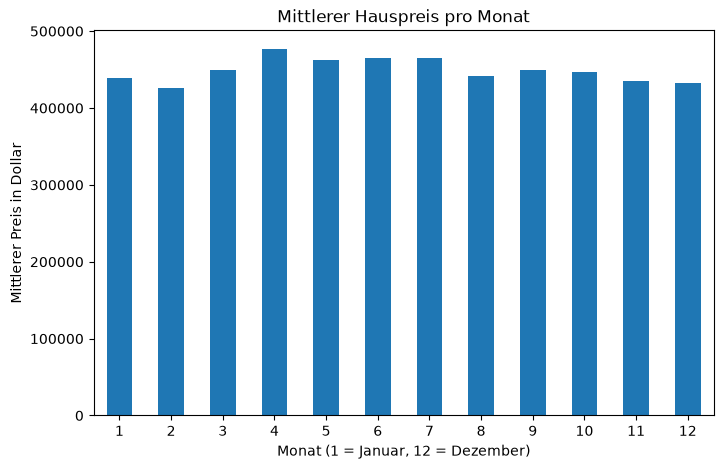

In [19]:
# 6. Zeigen: Balkendiagremm für Hypothese 2
def diagramm_h2(df):  # Kap. 13
    # Mittleren Preis (Median) für jeden Monat berechnen
    monatspreise = df.groupby("monat")["price"].median()  # Kap. 17

    # Balkendiagramm zeichnen, Monatszahlen gerade hinschreiben
    monatspreise.plot(kind="bar", rot=0)  # Kap. 20

    # Titel und Achsen beschriften
    plt.title("Mittlerer Hauspreis pro Monat")  # Kap. 20
    plt.xlabel("Monat (1 = Januar, 12 = Dezember)")  # Kap. 20
    plt.ylabel("Mittlerer Preis in Dollar")  # Kap. 20

    # Zahlen ohne 1e6 anzeigen
    plt.ticklabel_format(axis="y", style="plain")  # Kap. 20

    # Diagramm anzeigen
    plt.show()  # Kap. 20


diagramm_h2(df)

### Ergebnis Hypothese 2: Im Winter sind Häuser günstiger als im Sommer ✅

**Was sieht man?**
- Im Winter (Dezember, Januar, Februar) kostet ein Haus meistens ca. **430.000 $**.
- Im Sommer (Juni, Juli, August) kostet ein Haus meistens ca. **455.000 Dollar**.
- Am günstigsten ist der **Februar** mit ca. 426.500 $.
- Am teuersten ist der **April** mit ca. 477.000 $.
- Der Unterschied ist nicht sehr groß, aber man sieht ihn.

**Gegenprobe (weiter unten im Notebook):**
- Vielleicht werden im Winter nur kleinere Häuser verkauft? Darum habe ich den **Preis pro Quadratmeter** geprüft.
- Auch pro Quadratmeter ist der Winter günstiger: etwa **2.526 Dollar** im Winter und **2.643 Dollar** im Sommer.
- Das heißt: Der Winter ist wirklich günstiger, nicht nur wegen kleinerer Häuser.

**Vorsicht:**
Ich habe nur Daten von **einem Jahr** (Mai 2014 bis Mai 2015). Darum ist das ein Hinweis, keine Garantie.

**Was heißt das für Nicole?**
Wenn Nicole zwischen Dezember und Februar kauft, kann sie wahrscheinlich etwas Geld sparen. Im Frühling, vor allem im April, sind die Preise am höchsten.

**Hypothese 2 stimmt.**

### Ergebnis Hypothese 2: Im Winter sind Häuser günstiger als im Sommer

**Tabelle Hypothese2**

| Jahreszeit | Preis für ein Haus (meistens) | Preis pro Quadratmeter |
|---|---|---|
| Winter (Dez, Jan, Feb) | 430.000 Dollar | 2.526 Dollar |
| Sommer (Jun, Jul, Aug) | 455.000 Dollar | 2.643 Dollar |

- Am günstigsten ist der **Februar** (426.500 Dollar).
- Am teuersten ist der **April** (477.000 Dollar).
- Der Unterschied ist zwer nicht so groß, dennoch sieht man ihn. (Daten aus einem Jahr)


**Für Nicole bedeutet dies:..**
..wenn Nicole zwischen Dezember und Februar kauft, kann sie wahrscheinlich etwas Geld sparen. Im Frühling, vor allem im April, sind die Preise am höchsten.

**--> Hypothese 2 stimmt.**

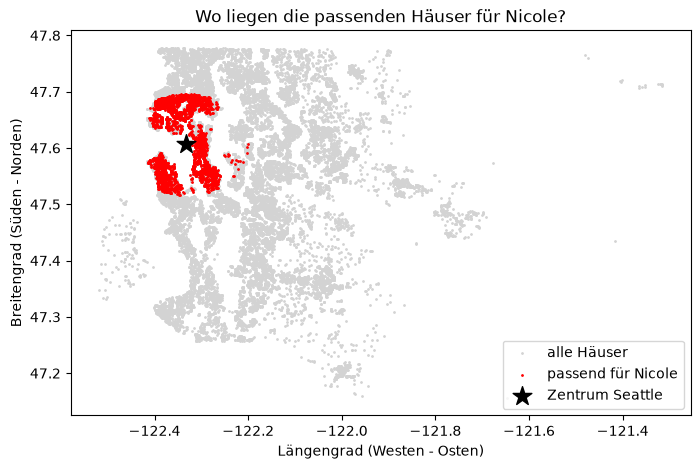

In [ ]:
# 6. Zeigen: Visuell Karte für Hypothese 3
def diagramm_h3(df, passende_haeuser):  # Kap. 13
    # Alle Häuser als graue Punkte zeichnen
    plt.scatter(df["long"], df["lat"], color="lightgrey", s=1, label="alle Häuser")  # Kap. 20

    # Passende Häuser für Nicole als rote Punkte zeichnen
    plt.scatter(passende_haeuser["long"], passende_haeuser["lat"], color="red", s=1, label="passend für Nicole")  # Kap. 20

    # Zentrum von Seattle als schwarzen Stern zeichnen
    plt.scatter(-122.3321, 47.6062, color="black", marker="*", s=200, label="Zentrum Seattle")  # Kap. 20

    # Titel und Achsen beschriften
    plt.title("Wo liegen die passenden Häuser für Nicole?")  # Kap. 20
    plt.xlabel("Längengrad (Westen - Osten)")  # Kap. 20
    plt.ylabel("Breitengrad (Süden - Norden)")  # Kap. 20

    # Erklärung der Farben anzeigen?
    plt.legend()  # Kap. 20

    # Diagramm anzeigen
    plt.show()  # Kap. 20


diagramm_h3(df, passende_haeuser)

### Ergebnis Hypothese 3: Nicole findet zentrale Häuser in ihrer Preisklasse 

**Was sieht man hier?**
- In der Nähe vom Zentrum (< 10 km) wurden **5.629 Häuser** verkauft.
- Davon passen **2.990 Häuser** in Nicoles Preisklasse (322.000 bis 645.000 Dollar).
- Das ist **mehr als jedes zweite Haus** (53 %).

**Wo liegen die passenden Häuser für Nicole?** (roten Punkte auf der Karte)
- Direkt im Zentrum gibt es kaum Häuser, wahrscheinlich überwiegned Büros und Wohnungen.
- Die passenden Häuser liegen **nördlich und südlich** der Innenstadt.

| Postleitzahl | Viertel | Passende Häuser |
|---|---|---|
| 98103 | Fremont, Wallingford, Green Lake | 311 |
| 98115 | Ravenna, Wedgwood | 274 |
| 98117 | Ballard | 250 |
| 98118 | Columbia City | 249 |
| 98144 | Beacon Hill | 221 |

**Für Nicole bedeutet dies:** Sie sollte in diesen 5 Vierteln suchen. Dort gibt es viele Häuser, die zentral liegen und gut in ihr Budget passen.

**--> Hypothese 3 stimmt.**

In [21]:
# Gegenprobe zu Hypothese 2: Preis pro Quadratmeter (also sind Objekte im Winter wirlklich günstiger als im Sommer?)
def gegenprobe_h2(df):  # Kap. 13
    # Wohnfläche von Quadratfuß in Quadratmeter umrechnen
    df["wohnflaeche_qm"] = df["sqft_living"] * 0.0929  # Kap. 4
    # Preis pro Quadratmeter berechnen
    df["preis_pro_qm"] = df["price"] / df["wohnflaeche_qm"]  # Kap. 4

    # Winter: Dezember, Januar, Februar
    winter = df[(df["monat"] == 12) | (df["monat"] == 1) | (df["monat"] == 2)]  # Kap. 16
    # Sommer: Juni, Juli, August
    sommer = df[(df["monat"] == 6) | (df["monat"] == 7) | (df["monat"] == 8)]  # Kap. 16

    # Mittleren Preis pro Quadratmeter für beide Jahreszeiten ausgeben
    print("Preis pro qm Winter:", round(winter["preis_pro_qm"].median()))  # Kap. 15
    print("Preis pro qm Sommer:", round(sommer["preis_pro_qm"].median()))  # Kap. 15

    # Mittleren Preis pro Quadratmeter für jeden Monat berechnen
    qm_pro_monat = df.groupby("monat")["preis_pro_qm"].median()  # Kap. 17
    # Ergebnis ausgeben
    print("Preis pro qm pro Monat:")  # Kap. 4
    print(qm_pro_monat.round())  # Kap. 4


gegenprobe_h2(df)

Preis pro qm Winter: 2526
Preis pro qm Sommer: 2643
Preis pro qm pro Monat:
monat
1    2526.000
2    2551.000
3    2720.000
4    2799.000
5    2669.000
6    2675.000
7    2602.000
8    2651.000
9    2617.000
10   2625.000
11   2563.000
12   2511.000
Name: preis_pro_qm, dtype: float64


## Zusammenfassung für Kundin: Nicole Johnson

### 3 Highlights 

**1. Zentral wohnen kostet mehr**
- Häuser bis 10 km vom Zentrum kosten meistens ca. 555.000 Dollar.
- Häuser weiter draußen kosten meistens ca. 416.000 Dollar.

**2. Im Winter sind Häuser etwas günstiger**
- Am günstigsten ist der Februar, am teuersten der April.
- Das gilt auch je Quadratmeter.
- Daten: nur von einem Jahr..also keine Garantie für Zukunft.

**3. Die passenden Häuser liegen nördlich und südlich der Innenstadt** 
- Mehr als jedes zweite zentrale Haus passt in Nicoles Preisklasse.
- Die meisten passenden Häuser gibt es in den folgenden 5 Vierteln: Fremont, Ravenna, Ballard, Columbia City und Beacon Hill.

### 3 Empfehlungen für Nicole

**1. Gezielt in den 5 Vierteln suchen**
- Postleitzahlen: 98103, 98115, 98117, 98118, 98144

**2. Budget von 322.000 bis 645.000 Dollar einplanen**
- In diesem Bereich findet sie viele zentrale Häuser.

**3. Den Kauf für Dezember bis Februar planen**
- Da sind die Preise am niedrigsten.
- Den Frühling, vor allem April, eher meiden.